# Dealing with Missing Data

We already reviewed Pandas operations for missing data, now let's apply this to clean a real data file. Keep in mind, there is no 100% correct way of doing this, and this notebook just serves as an example of some reasonable approaches to take on this data.

**Note**: Throughout this section, we will be slowly cleaning and adding features to the Ames Housing Dataset for use in the next section. Make sure to always be loading the same file name as in the notebook.

**2nd Note**: Some of the methods shown here may not lead to optimal performance, but instead are shown to display examples of various methods available.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Open a text file for reading using a relative file path.
# The file path '../DATA/Ames_Housing_Feature_Description.txt' refers to a text file named 'Ames_Housing_Feature_Description.txt'
# located in a folder named 'DATA' that is one level up from the current directory.
with open('.txt', 'r') as f:
    
    # Read the contents of the file and print them.
    # 'f.read()' reads the entire contents of the file as a string.
    print(f.read())


MSSubClass: Identifies the type of dwelling involved in the sale.	

        20	1-STORY 1946 & NEWER ALL STYLES
        30	1-STORY 1945 & OLDER
        40	1-STORY W/FINISHED ATTIC ALL AGES
        45	1-1/2 STORY - UNFINISHED ALL AGES
        50	1-1/2 STORY FINISHED ALL AGES
        60	2-STORY 1946 & NEWER
        70	2-STORY 1945 & OLDER
        75	2-1/2 STORY ALL AGES
        80	SPLIT OR MULTI-LEVEL
        85	SPLIT FOYER
        90	DUPLEX - ALL STYLES AND AGES
       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER
       150	1-1/2 STORY PUD - ALL AGES
       160	2-STORY PUD - 1946 & NEWER
       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER
       190	2 FAMILY CONVERSION - ALL STYLES AND AGES

MSZoning: Identifies the general zoning classification of the sale.
		
       A	Agriculture
       C	Commercial
       FV	Floating Village Residential
       I	Industrial
       RH	Residential High Density
       RL	Residential Low Density
       RP	Residential Low Density Park 
       RM

## Data


In [2]:
df = pd.read_csv(r"C:\Users\fafzali\Downloads\Machine learning\Code\Week 6\ames_outlierremoved.csv")

In [3]:
df.head()

,Order,PID,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,...,Screen.Porch,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition
0,1,526301100,1656,215000,20,RL,141.0,31770,Pave,NaN,...,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal
1,2,526350040,896,105000,20,RH,80.0,11622,Pave,NaN,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
2,3,526351010,1329,172000,20,RL,81.0,14267,Pave,NaN,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
3,4,526353030,2110,244000,20,RL,93.0,11160,Pave,NaN,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
4,5,527105010,1629,189900,60,RL,74.0,13830,Pave,NaN,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal


In [4]:
len(df.columns)

82

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2927 entries, 0 to 2926
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2927 non-null   int64  
 1   PID              2927 non-null   int64  
 2   area             2927 non-null   int64  
 3   price            2927 non-null   int64  
 4   MS.SubClass      2927 non-null   int64  
 5   MS.Zoning        2927 non-null   object 
 6   Lot.Frontage     2437 non-null   float64
 7   Lot.Area         2927 non-null   int64  
 8   Street           2927 non-null   object 
 9   Alley            198 non-null    object 
 10  Lot.Shape        2927 non-null   object 
 11  Land.Contour     2927 non-null   object 
 12  Utilities        2927 non-null   object 
 13  Lot.Config       2927 non-null   object 
 14  Land.Slope       2927 non-null   object 
 15  Neighborhood     2927 non-null   object 
 16  Condition.1      2927 non-null   object 
 17  Condition.2   

### Removing the PID

We already have an index, so we don't need the PID unique identifier for the regression we will perform later on.

In [6]:
df = df.drop('PID',axis=1)

In [7]:
len(df.columns)

81

## Observing NaN Features

In [8]:
df.isnull()

,Order,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,Lot.Shape,...,Screen.Porch,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition
0,False,False,False,False,False,False,False,False,True,False,...,False,False,True,True,True,False,False,False,False,False
1,False,False,False,False,False,False,False,False,True,False,...,False,False,True,False,True,False,False,False,False,False
2,False,False,False,False,False,False,False,False,True,False,...,False,False,True,True,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,True,False,...,False,False,True,True,True,False,False,False,False,False
4,False,False,False,False,False,False,False,False,True,False,...,False,False,True,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2922,False,False,False,False,False,False,False,False,True,False,...,False,False,True,False,True,False,False,False,False,False
2923,False,False,False,False,False,True,False,False,True,False,...,False,False,True,False,True,False,False,False,False,False
2924,False,False,False,False,False,False,False,False,True,False,...,False,False,True,False,False,False,False,False,False,False
2925,False,False,False,False,False,False,False,False,True,False,...,False,False,True,True,True,False,False,False,False,False


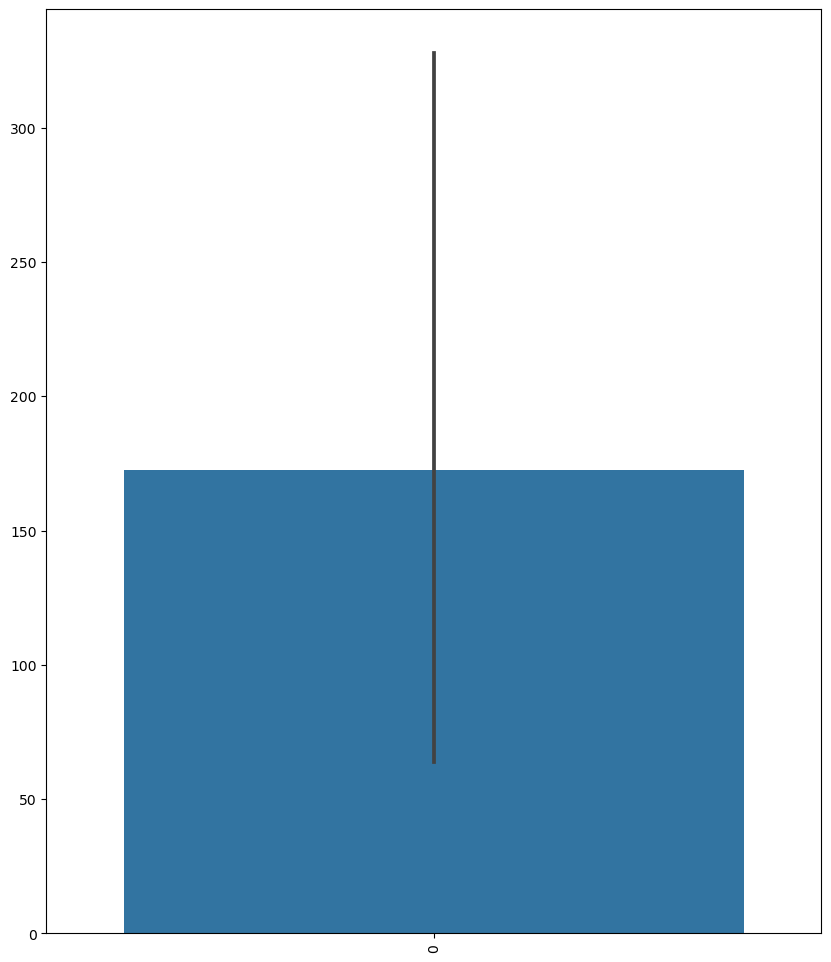

In [22]:
plt.figure(figsize=(10,12))
sns.barplot(df.isnull().sum().sort_values());
plt.xticks(rotation=90);

In [23]:
100* df.isnull().sum() / len(df)

Order             0.0
area              0.0
price             0.0
MS.SubClass       0.0
MS.Zoning         0.0
                 ... 
Misc.Val          0.0
Mo.Sold           0.0
Yr.Sold           0.0
Sale.Type         0.0
Sale.Condition    0.0
Length: 81, dtype: float64

In [24]:
# Define a function named 'percent_missing' that takes a DataFrame 'df' as its input.
def percent_missing(df):
    
    # Calculate the percentage of missing values for each column in the DataFrame.
    # 'df.isnull()' returns a DataFrame of Boolean values where 'True' represents missing values.
    # 'sum()' counts the number of 'True' values for each column.
    # 'len(df)' is the total number of rows in the DataFrame.
    # Multiplying by 100 converts the count to a percentage.
    percent_nan = 100 * df.isnull().sum() / len(df)
    
    # Filter out columns with no missing values (percentage = 0) and sort the remaining columns by their missing percentage.
    percent_nan = percent_nan[percent_nan > 0].sort_values()
    
    # Return the sorted Series containing the percentage of missing values for each column.
    return percent_nan


In [25]:
percent_nan = percent_missing(df)

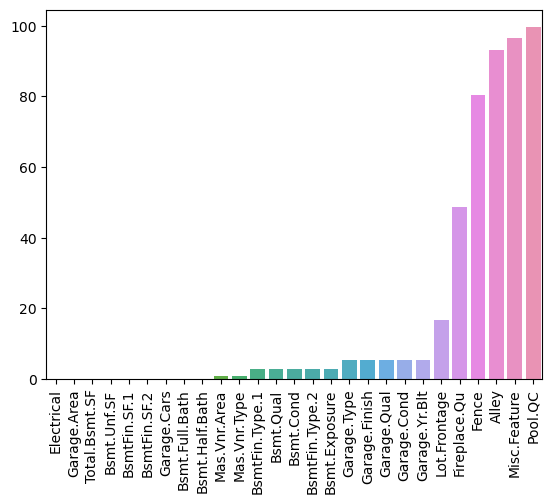

In [26]:
# Display a bar plot of the percentage of missing data for each feature.
# `percent_nan` contains the percentage of missing values for each feature, sorted by ascending order.
sns.barplot(x=percent_nan.index, y=percent_nan)

# Rotate the x-axis labels by 90 degrees for better readability.
plt.xticks(rotation=90);


## Dealing with Missing Data

We have previously discussed various techniques for handling missing data in your dataset. In this section, we will apply these techniques to clean the Ames Housing Dataset, preparing it for further analysis. Keep in mind that there is no one-size-fits-all solution for dealing with missing data, and the approaches demonstrated here are examples of reasonable strategies to consider for this specific dataset.

**Important Note 1:** Ensure that you consistently load the same dataset file throughout this notebook to maintain consistency.

**Important Note 2:** Some of the methods demonstrated here may not result in optimal performance but are included to illustrate different techniques available for handling missing data.

### Removing Features or Rows

If only a small portion of rows in your dataset have missing values relative to the total dataset size, it may be reasonable to consider removing those rows. While this approach does lead to a reduction in available data for training and testing, the impact on overall model performance is likely to be minimal when dealing with a small number of missing rows.

Additionally, there are situations where it makes sense to remove an entire feature (column) if it contains a significant number of missing values. However, before removing a feature, carefully assess why it has so many missing values. In some cases, missing values may carry valuable information, and you should consider whether null values could represent a meaningful category.

For example, consider a feature that represents the number of cars that can fit into a garage. If a property does not have a garage, it might have a null value in this column. Instead of removing the feature, it may be more appropriate to fill the missing values with zeros, as this better reflects the absence of a garage. Ultimately, your decision should be informed by domain expertise and a thorough understanding of the dataset.


## Working with Rows Missing Data

## Filling or Dropping Data?

In this section, we will explore the decision-making process for handling rows with missing data. Specifically, we will consider whether to fill in missing data or drop rows that contain missing values. The key question is when to choose one approach over the other.

### Choosing a Threshold

To decide whether to drop rows with missing data or address the missing values directly, we can establish a threshold. In this example, we will set a threshold of 1%. This means that if fewer than 1% of the rows in the dataset have missing data for a particular feature, we will consider simply dropping those rows instead of attempting to fill in the missing values. 

It's important to note that there is no universally correct threshold for this decision. The choice of threshold should be based on common sense and domain knowledge of the dataset. Extremely high thresholds (e.g., 50%) are typically not advisable, as they may result in the removal of a substantial portion of the data. Additionally, it's essential to explore the correlation of missing data with the dataset as a whole, as sometimes it may make more sense to drop the entire feature rather than individual rows.

### Understanding NaN Values

It's worth mentioning that, based on the text description of the features, many of the missing data entries are represented as NaN intentionally, serving as placeholders for zero or "none." Understanding the context and purpose of missing data in the dataset is crucial when making decisions about how to handle it.


## Example of Filling in Data : Basement Columns

(0.0, 1.0)

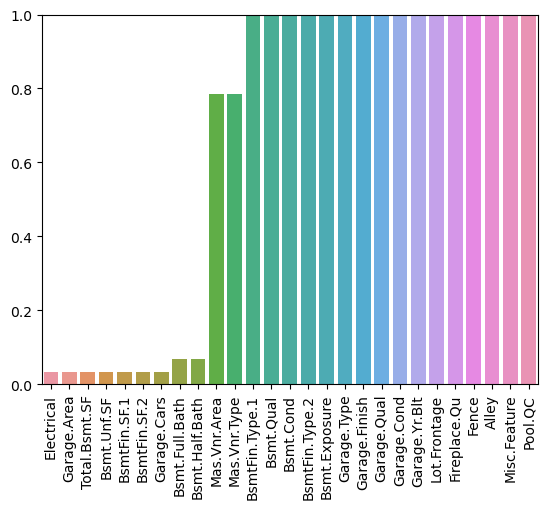

In [27]:
sns.barplot(x=percent_nan.index,y=percent_nan)
plt.xticks(rotation=90);

# Set 1% Threshold
plt.ylim(0,1)

Let's drop or fill the rows based on this data. You could either manually fill in the data (especially the Basement data based on the description text file) OR you could simply drop the row and not consider it. 

In [28]:
# Could also imply we should ex
percent_nan[percent_nan < 1]

Electrical        0.034165
Garage.Area       0.034165
Total.Bsmt.SF     0.034165
Bsmt.Unf.SF       0.034165
BsmtFin.SF.1      0.034165
BsmtFin.SF.2      0.034165
Garage.Cars       0.034165
Bsmt.Full.Bath    0.068329
Bsmt.Half.Bath    0.068329
Mas.Vnr.Area      0.785787
Mas.Vnr.Type      0.785787
dtype: float64

In [17]:
100/len(df)

0.0341646737273659

In [29]:
df[df['Total.Bsmt.SF'].isnull()]

,Order,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,Lot.Shape,...,Screen.Porch,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition
1341,1342,896,79000,20,RM,99.0,5940,Pave,NaN,IR1,...,0,0,NaN,MnPrv,NaN,0,4,2008,ConLD,Abnorml


In [30]:
df[df['Bsmt.Half.Bath'].isnull()]

,Order,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Alley,Lot.Shape,...,Screen.Porch,Pool.Area,Pool.QC,Fence,Misc.Feature,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition
1341,1342,896,79000,20,RM,99.0,5940,Pave,NaN,IR1,...,0,0,NaN,MnPrv,NaN,0,4,2008,ConLD,Abnorml
1497,1498,3820,284700,20,RL,123.0,47007,Pave,NaN,IR1,...,0,0,NaN,NaN,NaN,0,7,2008,WD,Normal


**Filling in data based on column names. There are 2 types of basement features, numerical and string descriptives.**

The numerical basement columns:

In [31]:
bsmt_num_cols = ['BsmtFin.SF.1', 'BsmtFin.SF.2', 'Bsmt.Unf.SF','Total.Bsmt.SF', 'Bsmt.Full.Bath', 'Bsmt.Half.Bath']
# Filling Missing Data in Basement-related Columns
# In this line of code, we are filling missing values in a subset of columns related to basements.
# - The `bsmt_num_cols` list contains the names of the basement-related columns that we want to fill.
# - We use the `.fillna(0)` method to replace missing values in these columns with zeros.
#   This is a common strategy for numerical columns where missing values can be interpreted as zero,
#   indicating that there is no basement-related information available for those rows.
#   Filling missing values with zeros ensures that these columns can be used in numerical calculations.
df[bsmt_num_cols] = df[bsmt_num_cols].fillna(0)


The string basement columns:

In [33]:
bsmt_str_cols =  ['Bsmt.Qual', 'Bsmt.Cond', 'Bsmt.Exposure', 'BsmtFin.Type.1', 'BsmtFin.Type.2']
df[bsmt_str_cols] = df[bsmt_str_cols].fillna('None')

In [34]:
percent_nan = percent_missing(df)

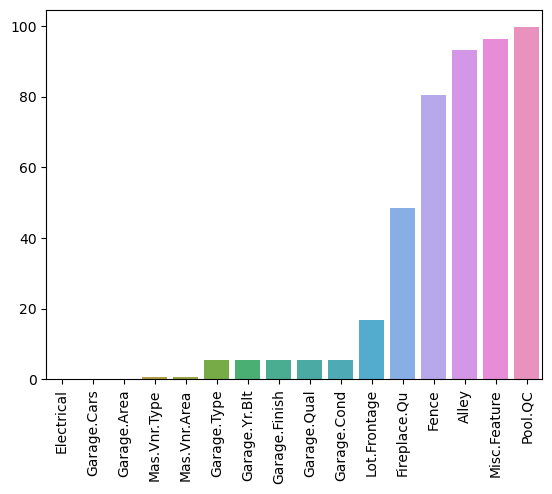

In [35]:
sns.barplot(x=percent_nan.index,y=percent_nan)
plt.xticks(rotation=90);

## Dropping Rows

A few of these features appear that it is just one or two rows missing the data. Based on our description .txt file of the dataset, we could also fill in these data points easily, and that is the more correct approach, but here we show how to drop in case you find yourself in a situation where it makes more sense to drop a row, based on missing column features.

    df.dropna() ---
        subset : array-like, optional
                Labels along other axis to consider, e.g. if you are dropping rows
                these would be a list of columns to include.

In [36]:
# Dropping Rows with Missing Data
# In this line of code, we are using the `dropna` method to remove rows that contain missing data.
# - The `axis=0` argument specifies that we are dropping rows (axis 0 refers to rows).
# - The `subset` argument specifies the subset of columns to consider when deciding whether a row has missing data.
#   In this case, we are checking the 'Electrical' and 'Garage Cars' columns for missing values.
#   If any of these columns have missing data for a particular row, that row will be dropped.
#   This operation helps clean the dataset by removing rows where critical information is missing.
df = df.dropna(axis=0, subset=['Electrical', 'Garage.Cars'])



In [37]:
percent_nan = percent_missing(df)

(0.0, 1.0)

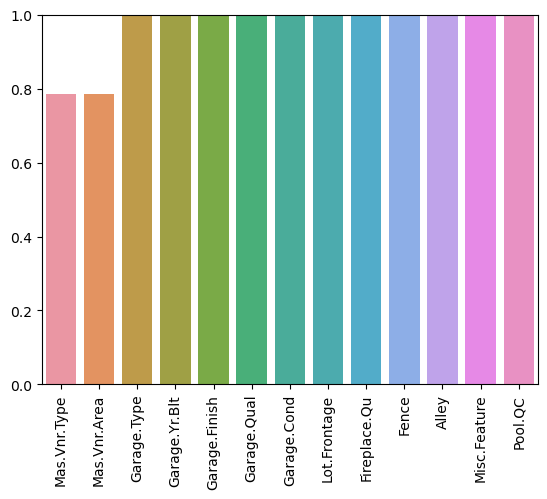

In [38]:
sns.barplot(x=percent_nan.index,y=percent_nan)
plt.xticks(rotation=90);
plt.ylim(0,1)


### Mas Vnr Feature 

Based on the Description Text File, Mas Vnr Type and Mas Vnr Area being missing (NaN) is likely to mean the house simply just doesn't have a masonry veneer, in which case, we will fill in this data as we did before.

In [39]:
df["Mas.Vnr.Type"] = df["Mas.Vnr.Type"].fillna("None")
df["Mas.Vnr.Area"] = df["Mas.Vnr.Area"].fillna(0)

C:\Users\fafzali\AppData\Local\Temp\ipykernel_31356\1672367191.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Mas.Vnr.Type"] = df["Mas.Vnr.Type"].fillna("None")
C:\Users\fafzali\AppData\Local\Temp\ipykernel_31356\1672367191.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Mas.Vnr.Area"] = df["Mas.Vnr.Area"].fillna(0)


In [40]:
percent_nan = percent_missing(df)

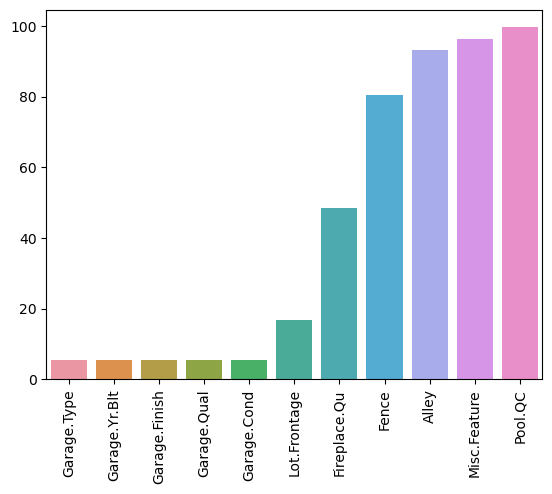

In [41]:
sns.barplot(x=percent_nan.index,y=percent_nan)
plt.xticks(rotation=90);

# Filling In Missing Column Data

Our previous approaches were based more on rows missing data, now we will take an approach based on the column features themselves, since larger percentages of the data appears to be missing.

### Garage Columns

Based on the data description, these NaN seem to indicate no garage, so we will substitute with "None" or 0.

In [42]:
df[['Garage.Type', 'Garage.Finish', 'Garage.Qual', 'Garage.Cond']]

,Garage.Type,Garage.Finish,Garage.Qual,Garage.Cond
0,Attchd,Fin,TA,TA
1,Attchd,Unf,TA,TA
2,Attchd,Unf,TA,TA
3,Attchd,Fin,TA,TA
4,Attchd,Fin,TA,TA
...,...,...,...,...
2922,Detchd,Unf,TA,TA
2923,Attchd,Unf,TA,TA
2924,NaN,NaN,NaN,NaN
2925,Attchd,RFn,TA,TA


In [49]:
gar_str_cols = ['Garage.Type', 'Garage.Finish', 'Garage.Qual', 'Garage.Cond']
df[gar_str_cols] = df[gar_str_cols].fillna('None')

C:\Users\fafzali\AppData\Local\Temp\ipykernel_31356\4106870898.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[gar_str_cols] = df[gar_str_cols].fillna('None')


In [50]:
df['Garage.Yr.Blt'] = df['Garage.Yr.Blt'].fillna(0)

C:\Users\fafzali\AppData\Local\Temp\ipykernel_31356\2498783024.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Garage.Yr.Blt'] = df['Garage.Yr.Blt'].fillna(0)


In [45]:
percent_nan = percent_missing(df)

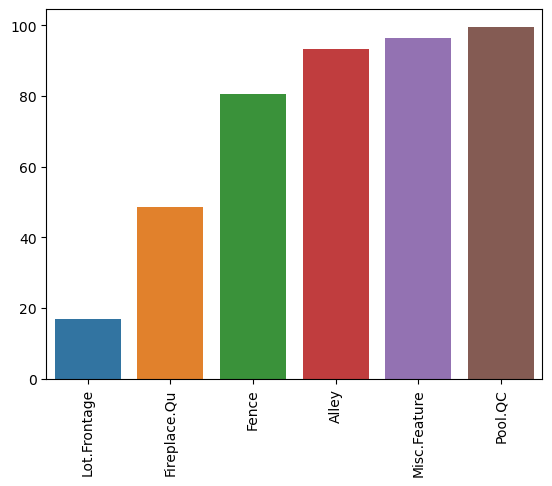

In [46]:
sns.barplot(x=percent_nan.index,y=percent_nan)
plt.xticks(rotation=90);

## Dropping Feature Columns

Sometimes you may want to take the approach that above a certain missing percentage threshold, you will simply remove the feature from all the data. For example if 99% of rows are missing a feature, it will not be predictive, since almost all the data does not have any value for it. In our particular data set, many of these high percentage NaN features are actually plasceholders for "none" or 0. But for the sake of showing variations on dealing with missing data, we will remove these features, instead of filling them in with the appropriate value.

In [47]:
percent_nan.index

Index(['Lot.Frontage', 'Fireplace.Qu', 'Fence', 'Alley', 'Misc.Feature',
       'Pool.QC'],
      dtype='object')

In [48]:
df[['Lot.Frontage', 'Fireplace.Qu', 'Fence', 'Alley', 'Misc.Feature','Pool.QC']]

,Lot.Frontage,Fireplace.Qu,Fence,Alley,Misc.Feature,Pool.QC
0,141.0,Gd,NaN,NaN,NaN,NaN
1,80.0,NaN,MnPrv,NaN,NaN,NaN
2,81.0,NaN,NaN,NaN,Gar2,NaN
3,93.0,TA,NaN,NaN,NaN,NaN
4,74.0,TA,MnPrv,NaN,NaN,NaN
...,...,...,...,...,...,...
2922,37.0,NaN,GdPrv,NaN,NaN,NaN
2923,NaN,NaN,MnPrv,NaN,NaN,NaN
2924,62.0,NaN,MnPrv,NaN,Shed,NaN
2925,77.0,TA,NaN,NaN,NaN,NaN


In [51]:
df = df.drop(['Pool.QC','Misc.Feature','Alley','Fence'],axis=1)

In [52]:
percent_nan = percent_missing(df)

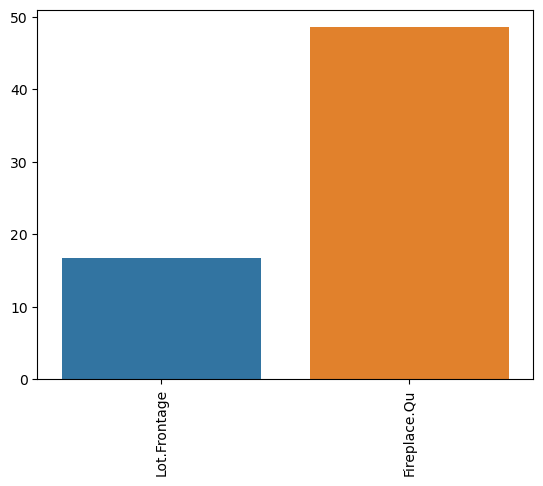

In [53]:
sns.barplot(x=percent_nan.index,y=percent_nan)
plt.xticks(rotation=90);

### Filling in Fireplace Quality based on Description Text

In [54]:
df['Fireplace.Qu'] = df['Fireplace.Qu'].fillna("None")

In [55]:
percent_nan = percent_missing(df)

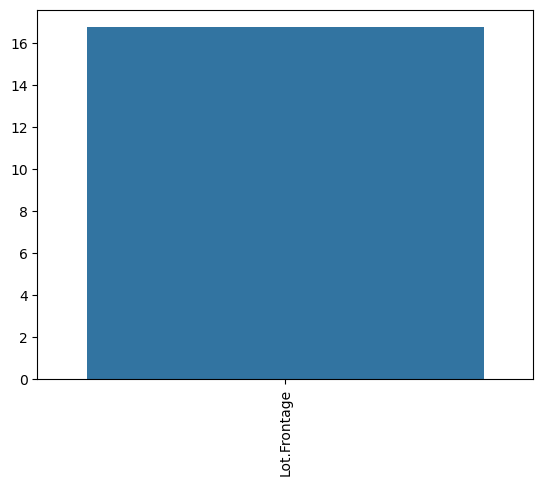

In [56]:
sns.barplot(x=percent_nan.index,y=percent_nan)
plt.xticks(rotation=90);

# [Imputation](https://en.wikipedia.org/wiki/Imputation_(statistics)) of Missing Data

To impute missing data, we need to decide what other filled in (no NaN values) feature most probably relates and is correlated with the missing feature data. In this particular case we will use:

Neighborhood: Physical locations within Ames city limits

LotFrontage: Linear feet of street connected to property

We will operate under the assumption that the Lot Frontage is related to what neighborhood a house is in.

In [57]:
df['Neighborhood'].unique()

array(['NAmes', 'Gilbert', 'StoneBr', 'NWAmes', 'Somerst', 'BrDale',
       'NPkVill', 'NridgHt', 'Blmngtn', 'NoRidge', 'SawyerW', 'Sawyer',
       'Greens', 'BrkSide', 'OldTown', 'IDOTRR', 'ClearCr', 'SWISU',
       'Edwards', 'CollgCr', 'Crawfor', 'Blueste', 'Mitchel', 'Timber',
       'MeadowV', 'Veenker', 'GrnHill', 'Landmrk'], dtype=object)

<Axes: xlabel='Lot.Frontage', ylabel='Neighborhood'>

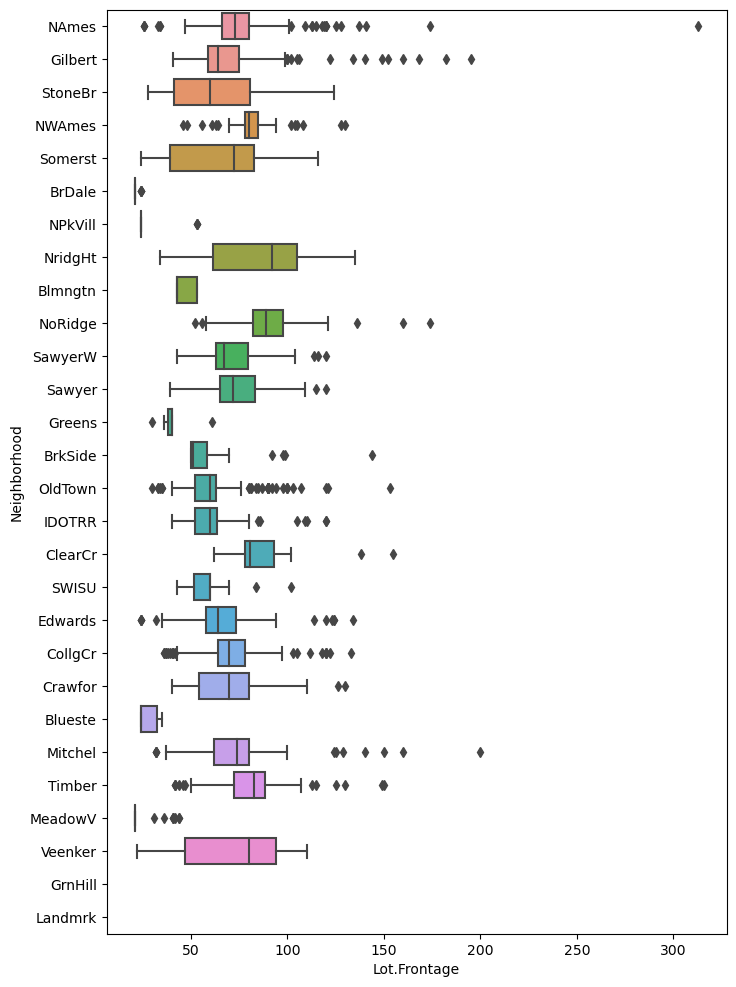

In [58]:
plt.figure(figsize=(8,12))
sns.boxplot(x='Lot.Frontage',y='Neighborhood',data=df,orient='h')

## Impute Missing Data based on other Features

There are more complex methods, but usually the simpler the better, it avoids building models on top of other models.

More Info on Options: https://scikit-learn.org/stable/modules/impute.html

In [59]:
df.groupby('Neighborhood')['Lot.Frontage']

In [61]:
k=df.groupby('Neighborhood')['Lot.Frontage'].mean()
k

Neighborhood
Blmngtn    46.900000
Blueste    27.300000
BrDale     21.500000
BrkSide    55.789474
ClearCr    88.150000
CollgCr    71.336364
Crawfor    69.951807
Edwards    64.794286
Gilbert    74.207207
Greens     41.000000
GrnHill          NaN
IDOTRR     62.383721
Landmrk          NaN
MeadowV    25.606061
Mitchel    75.144444
NAmes      75.210667
NPkVill    28.142857
NWAmes     81.517647
NoRidge    91.629630
NridgHt    84.184049
OldTown    61.777293
SWISU      59.068182
Sawyer     74.551020
SawyerW    70.669811
Somerst    64.549383
StoneBr    62.173913
Timber     81.303571
Veenker    72.000000
Name: Lot.Frontage, dtype: float64

In [63]:
df.groupby('Neighborhood')['Lot.Frontage'].mean()

Neighborhood
Blmngtn    46.900000
Blueste    27.300000
BrDale     21.500000
BrkSide    55.789474
ClearCr    88.150000
CollgCr    71.336364
Crawfor    69.951807
Edwards    64.794286
Gilbert    74.207207
Greens     41.000000
GrnHill          NaN
IDOTRR     62.383721
Landmrk          NaN
MeadowV    25.606061
Mitchel    75.144444
NAmes      75.210667
NPkVill    28.142857
NWAmes     81.517647
NoRidge    91.629630
NridgHt    84.184049
OldTown    61.777293
SWISU      59.068182
Sawyer     74.551020
SawyerW    70.669811
Somerst    64.549383
StoneBr    62.173913
Timber     81.303571
Veenker    72.000000
Name: Lot.Frontage, dtype: float64

## Transform Column

https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.transform.html

In [47]:
df.head()['Lot Frontage']

0    141.0
1     80.0
2     81.0
3     93.0
4     74.0
Name: Lot Frontage, dtype: float64

In [65]:
df[df['Lot.Frontage'].isnull()]

,Order,area,price,MS.SubClass,MS.Zoning,Lot.Frontage,Lot.Area,Street,Lot.Shape,Land.Contour,...,Open.Porch.SF,Enclosed.Porch,X3Ssn.Porch,Screen.Porch,Pool.Area,Misc.Val,Mo.Sold,Yr.Sold,Sale.Type,Sale.Condition
11,12,1187,185000,20,RL,NaN,7980,Pave,IR1,Lvl,...,21,0,0,0,0,500,3,2010,WD,Normal
14,15,1502,212000,120,RL,NaN,6820,Pave,IR1,Lvl,...,54,0,0,140,0,0,6,2010,WD,Normal
22,23,1674,216000,60,FV,NaN,7500,Pave,Reg,Lvl,...,96,0,0,0,0,0,1,2010,WD,Normal
23,24,1004,149000,20,RL,NaN,11241,Pave,IR1,Lvl,...,0,0,0,0,0,700,3,2010,WD,Normal
24,25,1078,149900,20,RL,NaN,12537,Pave,IR1,Lvl,...,0,0,0,0,0,0,4,2010,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2891,2895,1707,228000,20,RL,NaN,16669,Pave,IR1,Lvl,...,64,0,0,0,0,0,1,2006,WD,Normal
2894,2898,2514,250000,60,RL,NaN,11170,Pave,IR2,Lvl,...,0,0,0,0,0,0,4,2006,WD,Normal
2895,2899,1403,202000,20,RL,NaN,8098,Pave,IR1,Lvl,...,173,0,0,0,0,0,10,2006,WD,Normal
2909,2913,1652,146500,90,RL,NaN,11836,Pave,IR1,Lvl,...,0,0,0,0,0,0,3,2006,WD,Normal


In [49]:
df.iloc[21:26]['Lot Frontage']

21    85.0
22     NaN
23     NaN
24     NaN
25    65.0
Name: Lot Frontage, dtype: float64

In [66]:
df.groupby('Neighborhood')['Lot.Frontage'].transform(lambda val: val.fillna(val.mean()))

0       141.000000
1        80.000000
2        81.000000
3        93.000000
4        74.000000
           ...    
2922     37.000000
2923     75.144444
2924     62.000000
2925     77.000000
2926     74.000000
Name: Lot.Frontage, Length: 2925, dtype: float64

In [68]:
df.groupby('Neighborhood')['Lot.Frontage'].transform(lambda val: val.fillna(val.mean())).iloc[21:26]

21    85.000000
22    64.549383
23    75.210667
24    75.210667
25    65.000000
Name: Lot.Frontage, dtype: float64

In [52]:
df['Lot Frontage'] = df.groupby('Neighborhood')['Lot Frontage'].transform(lambda val: val.fillna(val.mean()))

In [69]:
percent_nan = percent_missing(df)

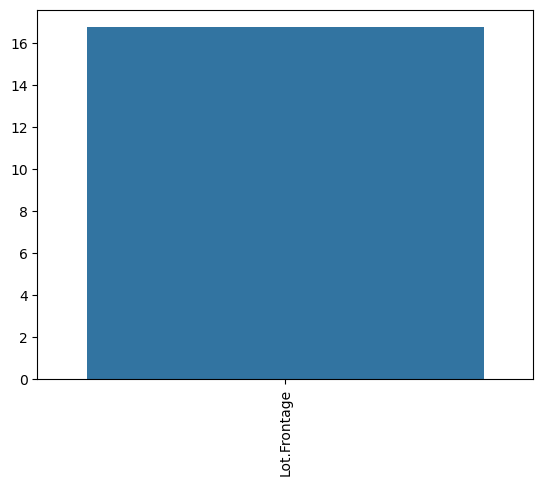

In [70]:
sns.barplot(x=percent_nan.index,y=percent_nan)
plt.xticks(rotation=90);

In [75]:
df['Lot.Frontage'] = df['Lot.Frontage'].fillna(0)

In [76]:
percent_nan = percent_missing(df)

In [77]:
percent_nan

Series([], dtype: float64)

Great! We no longer have any missing data in our entire data set! Keep in mind, we should eventually turn all these transformations into an easy to use function. For now, lets' save this dataset:

In [78]:
df.to_csv(r"C:\Users\fafzali\Downloads\Machine learning\Code\Week 6\ames_nomissed.csv",index=False)

----